<a href="https://colab.research.google.com/github/devanshmayatra/revvue/blob/bert-tiny-experiments/experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RevVue: Data Preparation and Experiments

This notebook prepares review data for comparing BERT models. All experiments use the same sentiment labels and train/validation/test splits.

## Where should I start?

Run **Setup** first, then choose the route that matches what you need:

| What you want to do | Sections to run |
|---|---|
| Prepare the dataset from the original reviews | **Setup → A → C** |
| Start experimenting with the published dataset | **Setup → B → C** |

### Section A — Build and explore the dataset
We load and clean the original reviews, explore the data, and test our hypotheses. We then create sentiment labels, split the reviews into training, validation, and test sets, and export the splits for sharing.

Run this section when preparing a new dataset version.

### Section B — Load the prepared dataset
We download the published splits from GitHub. These files already contain cleaned review text, sentiment labels, and fixed split assignments.

Start here after Setup if you want to use the prepared data. You can skip running Section A; its analysis remains available to read.

### Section C — Prepare inputs for a model
We tokenize the reviews for the selected model and create three DataLoaders. Both routes lead to this section.

When changing models, reuse the same splits and rerun Section C with the appropriate tokenizer.

**Choose either A or B, then continue to C.** Section B requires the dataset release to have been published.

## Setup

We load the libraries and define the settings shared across experiments. The random seed makes the splits repeatable. Model-specific tokenization happens after the data has been prepared or downloaded.

In [1]:
%pip install -q gdown datasets qbstyles "optuna>=4,<5" "transformers[torch]==5.24.1" "huggingface-hub>=1.32,<2"
import transformers
print(transformers.__version__)

5.24.1


In [2]:
from pathlib import Path
import html
import json
import re
import unicodedata

# for data loading and cleaning up the data
import gdown
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup

# for hypotheses analysis and visuals
from scipy.stats import chisquare, kruskal, spearmanr
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from qbstyles import mpl_style

# for data prep for the experiments
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict, load_dataset
from torch.utils.data import DataLoader

# for the experiments
import gc
import optuna
import torch.nn.functional as F

from sklearn.metrics import accuracy_score, f1_score, classification_report
from transformers import (
    AutoTokenizer,
    DataCollatorWithPadding,
    set_seed,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
)

# bert
from transformers import BertConfig, BertForSequenceClassification

# additional settings and mappings
mpl_style(dark=True, minor_ticks=False)

SEED = 42
MODEL_NAME = "prajjwal1/bert-tiny"
MAX_LENGTH = 256
BATCH_SIZE = 16

id2label = {0: "negative", 1: "neutral", 2: "positive"}
label2id = {name: label for label, name in id2label.items()}

set_seed(SEED)

## A. Build the prepared datasets

We begin with the original reviews and work through the full preparation process.

- **A0:** preprocessing, cleaning, exploratory analysis, and hypothesis tests.
- **A1:** select the review text and create sentiment labels.
- **A2:** check repeated text before splitting.
- **A3:** create fixed training, validation, and test splits.
- **A4:** export the splits for sharing.

To use the published datasets, skip Section A and continue to `Section B` after running Setup.

### A0. Preprocessing, cleaning, and exploratory analysis

We correct data types, handle missing values, and clean the review text. We then examine rating distributions, review lengths, and changes over time, using hypothesis tests and effect sizes to interpret the findings.

The following analysis describes the cleaned dataset before the additional modeling preparation in A1–A4.

In [ ]:
dataset_path = Path("/content/music_reviews.tsv")

gdown.download(
    id="1V4467Zzfu1S8Gya4oI6Evc0D_rtyb3jX",
    output=str(dataset_path),
    quiet=False,
)

df = pd.read_csv(dataset_path, sep="\t", on_bad_lines="skip")
print("Dataset shape:", df.shape)
df.head()

Downloading...
From (original): https://drive.google.com/uc?id=1V4467Zzfu1S8Gya4oI6Evc0D_rtyb3jX
From (redirected): https://drive.google.com/uc?id=1V4467Zzfu1S8Gya4oI6Evc0D_rtyb3jX&confirm=t&uuid=55ec77c5-92fc-4c0b-87e1-a5ddc846e39a
To: /content/music_reviews.tsv
100%|██████████| 629M/629M [00:09<00:00, 65.0MB/s]


Dataset shape: (1681484, 15)


,marketplace,customer_id,review_id,product_id,product_parent,product_title,product_category,star_rating,helpful_votes,total_votes,vine,verified_purchase,review_headline,review_body,review_date
0,US,10293599,R14LVB34Z2Z53I,B000YMOQZY,262935067,Knockin' On Heaven's Door,Digital_Music_Purchase,5.0,0.0,0.0,N,Y,favorites,Great rendition. Great song,2015-08-31
1,US,6087195,R2M0R9CWPC82LT,B00ISAEC80,452318038,Flawless,Digital_Music_Purchase,5.0,0.0,0.0,N,Y,Five Stars,A good music to listen.,2015-08-31
2,US,33717063,RQNQI2R3BM52A,B00VBB6AVU,675969129,Scandal of Grace,Digital_Music_Purchase,4.0,0.0,0.0,N,Y,Good,Not as good as the original but I needed to he...,2015-08-31
3,US,14948020,RTUIX1135HUAB,B008A5POJO,282925893,I Surrender (Live),Digital_Music_Purchase,5.0,0.0,0.0,N,Y,Wonderful lyrics! Makes you feel like praying,Time to worship and surrender with this song. ...,2015-08-31
4,US,21694522,RE3QSAT8TL010,B014CW2RN4,109077793,We Are Young (Jersey Club),Digital_Music_Purchase,4.0,0.0,0.0,N,Y,Hot remix but took short,So this should be longer....but love this song:),2015-08-31


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nMissing values:")
print(df.isnull().sum())

Rows: 1681484
Columns: 15

Missing values:
marketplace            0
customer_id            0
review_id              0
product_id             0
product_parent         0
product_title          0
product_category       0
star_rating            2
helpful_votes          2
total_votes            2
vine                   2
verified_purchase      2
review_headline       59
review_body          114
review_date           76
dtype: int64


### A0.1 Data preprocessing

The Amazon Digital Music Purchase Reviews dataset contains **1,681,484 records and 15 original features**.

The following preprocessing steps were performed:

1. **Data Type Conversion:** Converted identifiers to strings, ratings and vote counts to nullable integers, review dates to datetime, and categorical attributes to appropriate data types.
2. **Boolean Transformation:** Converted `verified_purchase` and `vine` values (Y/N) into boolean features (`is_verified` and `is_vine`).
3. **Temporal Feature Extraction:** Extracted `review_year` and `review_month` to support time-based analysis.
4. **Text Feature Extraction:** Created `review_word_count` and `review_char_count` to measure review length.
5. **Helpfulness Ratio:** Calculated the proportion of helpful votes using `helpful_votes / total_votes`, leaving the ratio undefined when total votes equal zero.

### Preprocessing Summary

- **Original Features:** 15
- **New Features:** 7
- **Total Features:** 22
- **Records Retained During Preprocessing:** 1,681,484

Missing values were preserved for the subsequent data cleaning stage. Malformed records encountered during initial TSV import were skipped using `on_bad_lines="skip"`.

These transformations prepare the dataset for data cleaning, exploratory analysis, and statistical testing.

In [ ]:
df_preprocessed = df.copy()

print("\nColumn Information:")
df_preprocessed.info()


Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1681484 entries, 0 to 1681483
Data columns (total 15 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   marketplace        1681484 non-null  object 
 1   customer_id        1681484 non-null  int64  
 2   review_id          1681484 non-null  object 
 3   product_id         1681484 non-null  object 
 4   product_parent     1681484 non-null  int64  
 5   product_title      1681484 non-null  object 
 6   product_category   1681484 non-null  object 
 7   star_rating        1681482 non-null  float64
 8   helpful_votes      1681482 non-null  float64
 9   total_votes        1681482 non-null  float64
 10  vine               1681482 non-null  object 
 11  verified_purchase  1681482 non-null  object 
 12  review_headline    1681425 non-null  object 
 13  review_body        1681370 non-null  object 
 14  review_date        1681408 non-null  object 
dtypes: float64(

In [ ]:
id_cols = [
    "customer_id", "review_id", "product_id", "product_parent"
]

for cols in id_cols:
    df_preprocessed[cols] = df_preprocessed[cols].astype("string")

df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1681484 entries, 0 to 1681483
Data columns (total 15 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   marketplace        1681484 non-null  object 
 1   customer_id        1681484 non-null  string 
 2   review_id          1681484 non-null  string 
 3   product_id         1681484 non-null  string 
 4   product_parent     1681484 non-null  string 
 5   product_title      1681484 non-null  object 
 6   product_category   1681484 non-null  object 
 7   star_rating        1681482 non-null  float64
 8   helpful_votes      1681482 non-null  float64
 9   total_votes        1681482 non-null  float64
 10  vine               1681482 non-null  object 
 11  verified_purchase  1681482 non-null  object 
 12  review_headline    1681425 non-null  object 
 13  review_body        1681370 non-null  object 
 14  review_date        1681408 non-null  object 
dtypes: float64(3), object(8), string

In [ ]:
numeric_cols = [
    "star_rating",
    "helpful_votes",
    "total_votes"
]

for col in numeric_cols:
    df_preprocessed[col] = pd.to_numeric(
        df_preprocessed[col],
        errors="coerce"
    ).astype("Int64")

df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1681484 entries, 0 to 1681483
Data columns (total 15 columns):
 #   Column             Non-Null Count    Dtype 
---  ------             --------------    ----- 
 0   marketplace        1681484 non-null  object
 1   customer_id        1681484 non-null  string
 2   review_id          1681484 non-null  string
 3   product_id         1681484 non-null  string
 4   product_parent     1681484 non-null  string
 5   product_title      1681484 non-null  object
 6   product_category   1681484 non-null  object
 7   star_rating        1681482 non-null  Int64 
 8   helpful_votes      1681482 non-null  Int64 
 9   total_votes        1681482 non-null  Int64 
 10  vine               1681482 non-null  object
 11  verified_purchase  1681482 non-null  object
 12  review_headline    1681425 non-null  object
 13  review_body        1681370 non-null  object
 14  review_date        1681408 non-null  object
dtypes: Int64(3), object(8), string(4)
memory usage: 1

In [ ]:
df_preprocessed["review_date"] = pd.to_datetime(
    df_preprocessed["review_date"],
    errors="coerce"
)

In [ ]:
for col in ["marketplace", "product_category"]:
    df_preprocessed[col] = df_preprocessed[col].astype("category")

In [ ]:
for col in [
    "product_title","review_headline","review_body"
]:
    df_preprocessed[col] = (
        df_preprocessed[col].astype("string")
    )

In [ ]:
df_preprocessed["is_verified"] = (
    df_preprocessed["verified_purchase"]
    .map({"Y": True, "N": False})
    .astype("boolean")
)

df_preprocessed["is_vine"] = (
    df_preprocessed["vine"]
    .map({"Y": True, "N": False})
    .astype("boolean")
)

In [ ]:
df_preprocessed["review_year"] = (
    df_preprocessed["review_date"].dt.year
)

df_preprocessed["review_month"] = (
    df_preprocessed["review_date"].dt.month
)

In [ ]:
df_preprocessed["review_word_count"] = (
    df_preprocessed["review_body"].str.count(r"\S+")
)

df_preprocessed["review_char_count"] = (
    df_preprocessed["review_body"].str.len()
)

In [ ]:
df_preprocessed["helpfulness_ratio"] = (
    df_preprocessed["helpful_votes"] /
    df_preprocessed["total_votes"].where(
        df_preprocessed["total_votes"] > 0
    )
)

In [ ]:
print(df_preprocessed.shape, "\n")
print(df_preprocessed.info())

(1681484, 22) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1681484 entries, 0 to 1681483
Data columns (total 22 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   marketplace        1681484 non-null  category      
 1   customer_id        1681484 non-null  string        
 2   review_id          1681484 non-null  string        
 3   product_id         1681484 non-null  string        
 4   product_parent     1681484 non-null  string        
 5   product_title      1681484 non-null  string        
 6   product_category   1681484 non-null  category      
 7   star_rating        1681482 non-null  Int64         
 8   helpful_votes      1681482 non-null  Int64         
 9   total_votes        1681482 non-null  Int64         
 10  vine               1681482 non-null  object        
 11  verified_purchase  1681482 non-null  object        
 12  review_headline    1681425 non-null  string        
 13  review_body

In [ ]:
df_preprocessed.head()

,marketplace,customer_id,review_id,product_id,product_parent,product_title,product_category,star_rating,helpful_votes,total_votes,...,review_headline,review_body,review_date,is_verified,is_vine,review_year,review_month,review_word_count,review_char_count,helpfulness_ratio
0,US,10293599,R14LVB34Z2Z53I,B000YMOQZY,262935067,Knockin' On Heaven's Door,Digital_Music_Purchase,5,0,0,...,favorites,Great rendition. Great song,2015-08-31,True,False,2015.0,8.0,4,29,<NA>
1,US,6087195,R2M0R9CWPC82LT,B00ISAEC80,452318038,Flawless,Digital_Music_Purchase,5,0,0,...,Five Stars,A good music to listen.,2015-08-31,True,False,2015.0,8.0,5,23,<NA>
2,US,33717063,RQNQI2R3BM52A,B00VBB6AVU,675969129,Scandal of Grace,Digital_Music_Purchase,4,0,0,...,Good,Not as good as the original but I needed to he...,2015-08-31,True,False,2015.0,8.0,22,103,<NA>
3,US,14948020,RTUIX1135HUAB,B008A5POJO,282925893,I Surrender (Live),Digital_Music_Purchase,5,0,0,...,Wonderful lyrics! Makes you feel like praying,Time to worship and surrender with this song. ...,2015-08-31,True,False,2015.0,8.0,15,93,<NA>
4,US,21694522,RE3QSAT8TL010,B014CW2RN4,109077793,We Are Young (Jersey Club),Digital_Music_Purchase,4,0,0,...,Hot remix but took short,So this should be longer....but love this song:),2015-08-31,True,False,2015.0,8.0,8,48,<NA>


In [ ]:
df_preprocessed.dtypes

,0
marketplace,category
customer_id,string[python]
review_id,string[python]
product_id,string[python]
product_parent,string[python]
product_title,string[python]
product_category,category
star_rating,Int64
helpful_votes,Int64
total_votes,Int64


### A0.2 Data cleaning

Data Cleaning is the process of identifying and correcting or removing inaccurate, incomplete, duplicate, inconsistent, or irrelevant data to improve data quality so that it is ready for model training.

The following data cleaning steps were peformed:


* **Data Quality Assessment** - Examining column data types, missing-value counts, missing-value percentages, and unique-value counts to assess data quality.

* **Duplicate Detection and Removal** - Identifying and removing duplicate records, if any, while retaining the first occurrence.

* **Missing Value Handling and Rating Validation** - Identifying and removing records with missing or blank review text and missing star ratings. Additionally, checking for invalid star ratings outside the valid range of 1–5.

* **HTML Formatting Inspection and Cleaning** - Identifying and removing HTML tags and decoding HTML entities in review text to ensure clean input for sentiment analysis.

* **Final Data Validation** - Performing final quality checks to ensure the cleaned dataset contains valid ratings, non-empty review text, and no exact duplicate records.

Before data cleaning, total records - **1,681,484**

After data cleaning, total recods - **1,681,368**








In [ ]:
# Inspecting column data types, missing-value counts, missing-value percentages, and unique-value counts

column_summary = pd.DataFrame({
    "Column": df_preprocessed.columns,
    "Data Type": df_preprocessed.dtypes.values,
    "Missing Count": df_preprocessed.isna().sum().values,
    "Missing %": (
        df_preprocessed.isna().mean().values * 100
    ).round(2),
    "Unique Values": df_preprocessed.nunique().values
})

display(column_summary)

,Column,Data Type,Missing Count,Missing %,Unique Values
0,marketplace,category,0,0.00,1
1,customer_id,string[python],0,0.00,796587
2,review_id,string[python],0,0.00,1681484
3,product_id,string[python],0,0.00,699450
4,product_parent,string[python],0,0.00,644045
5,product_title,string[python],0,0.00,499915
6,product_category,category,0,0.00,3
7,star_rating,Int64,2,0.00,5
8,helpful_votes,Int64,2,0.00,201
9,total_votes,Int64,2,0.00,235


In [ ]:
# Identifying exact duplicate rows
print("Exact duplicate rows:", df_preprocessed.duplicated().sum())

# Removing duplicate rows while retaining the first occurrence
rows_before = len(df_preprocessed)

df_preprocessed = df_preprocessed.drop_duplicates(
    keep="first"
).reset_index(drop=True)

# Calculating the number of duplicate rows removed
rows_after = len(df_preprocessed)

print("Duplicate rows removed:", rows_before - rows_after)
print("Remaining rows:", rows_after)

Exact duplicate rows: 0
Duplicate rows removed: 0
Remaining rows: 1681484


In [ ]:
# Identifying missing values in review text and star ratings, which are essential for sentiment classification

# Removing records with missing review text or star ratings

rows_before = len(df_preprocessed)

df_preprocessed = df_preprocessed.dropna(
    subset=["review_body", "star_rating"]
).copy()

In [ ]:
# Removing records containing only whitespace in the review body

df_preprocessed = df_preprocessed[
    df_preprocessed["review_body"].str.strip().ne("")
].copy()

In [ ]:
# Validating star ratings to ensure they are suitable for sentiment labeling and subsequent model evaluation

print(
    df_preprocessed["star_rating"]
    .value_counts(dropna=False)
    .sort_index()
)

star_rating
1      48771
2      24927
3      62149
4     206455
5    1339068
Name: count, dtype: Int64


In [ ]:
# Inspecting review text for HTML tags and encoded entities inherited from the original web-based source

TAG = re.compile(
    r"</?[a-z][^>]*>",
    re.IGNORECASE
)

ENTITY = re.compile(
    r"&(?:[a-z][a-z0-9]+|#\d+|#x[0-9a-f]+);",
    re.IGNORECASE
)

review_text = df_preprocessed["review_body"].astype("string")

html_tags = review_text.str.contains(
    TAG,
    na=False
)

html_entities = review_text.str.contains(
    ENTITY,
    na=False
)

print("Reviews containing HTML-like tags:", html_tags.sum())
print("Reviews containing HTML entities:", html_entities.sum())

Reviews containing HTML-like tags: 147426
Reviews containing HTML entities: 89495


In [ ]:
# Cleaning review body column from these tags

# Creating a function

def clean_text(value):

    # Handle missing text
    if pd.isna(value):
        return ""

    # Convert to string and decode HTML entities
    text = html.unescape(str(value))

    # Remove HTML tags when detected
    if TAG.search(text):
        text = BeautifulSoup(
            text,
            "html.parser"
        ).get_text(" ")

    # Normalize Unicode
    text = unicodedata.normalize("NFC", text)

    # Replace control characters with spaces
    text = "".join(
        " " if (
            unicodedata.category(char) in ("Cc", "Cf")
            and char not in ("\n", "\t")
        ) else char
        for char in text
    )

    # Remove unnecessary whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
# Applying cleaning function

df_preprocessed["clean_review"] = (
    df_preprocessed["review_body"]
    .map(clean_text)
)

print("Text cleaning completed successfully!")

# Identify reviews where cleaning made changes
changed_reviews = df_preprocessed[
    df_preprocessed["review_body"].fillna("") !=
    df_preprocessed["clean_review"]
]

print("Total reviews modified:", len(changed_reviews))

Text cleaning completed successfully!
Total reviews modified: 621270


In [ ]:
# Identifying reviews that become empty after removing HTML tags and decoding HTML entities

empty_reviews = df_preprocessed[
    df_preprocessed["clean_review"].str.len() == 0
]

print("Total empty reviews:", len(empty_reviews))

display(
    empty_reviews[["review_body", "clean_review"]].head(20)
)

Total empty reviews: 2


,review_body,clean_review
155859,&#60;insert something deep here&#62;,
203638,...,


In [ ]:
# Removing missing, empty, or whitespace-only cleaned reviews to ensure valid text inputs for model

rows_before = len(df_preprocessed)

df_preprocessed = df_preprocessed[
    df_preprocessed["clean_review"].notna() &
    df_preprocessed["clean_review"].str.strip().ne("")
].copy()

print("Rows removed:", rows_before - len(df_preprocessed))
print("Remaining rows:", len(df_preprocessed))

Rows removed: 2
Remaining rows: 1681368


Final cleaning validation

In [ ]:
# Reset index
df_preprocessed = df_preprocessed.reset_index(drop=True)

# Essential fields must be present
assert df_preprocessed["clean_review"].notna().all()
assert df_preprocessed["star_rating"].notna().all()

# No blank review text
assert df_preprocessed["clean_review"].str.len().gt(0).all()

# Ratings must be valid
assert df_preprocessed["star_rating"].isin(
    [1, 2, 3, 4, 5]
).all()


# No fully duplicated rows
assert df_preprocessed.duplicated().sum() == 0

print("All essential cleaning checks passed!")
print("Final cleaned shape:", df_preprocessed.shape)

All essential cleaning checks passed!
Final cleaned shape: (1681368, 23)


### A0.3 Exploratory data analysis

Before modeling, we explore the cleaned dataset ($1{,}681{,}368$ reviews, $23$ features). We focus on the target we will predict (the star rating) and the input the model will read (the review text).

We answer three questions, each with a different hypothesis test:

| # | Question | Hypothesis test | Effect size |
|---|---|---|---|
| 3.1 | Are star ratings evenly distributed? | Chi-square goodness-of-fit | Cohen's $w$ |
| 3.2 | Does review length differ by rating? | Kruskal–Wallis $H$ test | $\eta^2_H$ |
| 3.3 | Do ratings drift over time? | Spearman rank correlation | $\rho_s$ |

With over $1.6$ million reviews, almost any difference is statistically significant. For every test we therefore also report an effect size, which shows whether the difference actually matters. Each finding leads to a concrete decision for the modeling experiments that follow.

In [ ]:
eda = pd.DataFrame({
    "rating": df_preprocessed["star_rating"].astype(int),
    "words":  df_preprocessed["clean_review"].str.count(r"\S+").astype(int),
    "year":   df_preprocessed["review_date"].dt.year,
})

fmt_p = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

print(f"{len(eda):,} reviews | {df_preprocessed.shape[1]} features")

1,681,368 reviews | 23 features


#### 3.1 Rating Distribution

The star rating is the variable we will predict, so we first check whether all ratings are equally represented. A **chi-square goodness-of-fit test** compares the observed count of each rating, $O_r$, with the count expected if all five ratings were equally likely, $E_r = N/5$:

$$
\begin{aligned}
H_0 &: p_1 = p_2 = p_3 = p_4 = p_5 = 0.2 \\
H_1 &: \text{at least one } p_r \neq 0.2
\end{aligned}
\qquad \alpha = 0.05
$$

$$
\chi^2 = \sum_{r=1}^{5} \frac{(O_r - E_r)^2}{E_r} \qquad\qquad w = \sqrt{\frac{\chi^2}{N}}
$$

Cohen's $w$ measures how far the distribution is from uniform: $0.1$ is small, $0.3$ is medium, and $0.5$ is large.

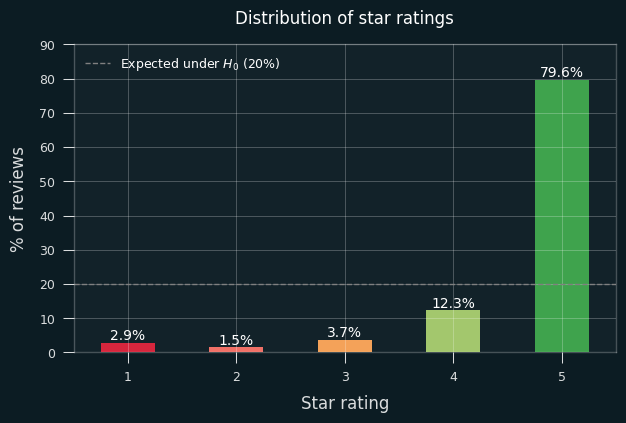

χ² = 3,798,051, p < 0.001, Cohen's w = 1.50 | 5★ : 2★ = 54 : 1


In [ ]:
counts = eda["rating"].value_counts().sort_index()
pct = counts / counts.sum() * 100

chi2, p = chisquare(counts)
w = np.sqrt(chi2 / counts.sum())

colors = ["#D7263D", "#F07167", "#F4A259", "#A3C76D", "#3FA34D"]  # for more visually intuitive colors
ax = pct.plot(kind="bar", color=colors, rot=0, figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
expected = ax.axhline(20, color="gray", linestyle="--", linewidth=1, label="Expected under $H_0$ (20%)")
ax.set(title="Distribution of star ratings", xlabel="Star rating", ylabel="% of reviews", ylim=(0, 90))
ax.legend(handles=[expected], frameon=False)
plt.show()

print(f"χ² = {chi2:,.0f}, {fmt_p(p)}, Cohen's w = {w:.2f} | 5★ : 2★ = {counts[5] / counts[2]:.0f} : 1")

##### Conclusion 1: The ratings are heavily imbalanced, so we group them into three classes.

First, we reject $H_0$ ($\chi^2 \approx 3.8 \times 10^6$, $p < 0.001$). Cohen's $w \approx 1.50$ is three times the threshold for a large effect, so the ratings are far from uniform.

As we can see from the plot above, $79.6\%$ of reviews are 5★, while 2★ makes up only $1.5\%$, a ratio of about $54 : 1$. We can also observe that the distribution is J-shaped. This pattern is typical of online reviews, where people are more likely to write when they love or dislike something than when they feel lukewarm.

Classes this small (like 1, 2, and 3-starred reviews) are hard for a model to learn. We propose merging neighbouring ratings into three sentiment classes: `Negative` (1–2★, $4.4\%$), `Neutral` (3–4★, $16.0\%$), and `Positive` (5★, $79.6\%$). The grouping reduces the imbalance from $54 : 1$ to about $18 : 1$. However, even after grouping, a model that always predicts *Excellent* would be $79.6\%$ accurate. The split must therefore be stratified by class, and performance measured with `macro-F1` rather than accuracy.

#### 3.2 Review Length by Rating

The review text is what the model will read, so we check how long reviews are and whether length differs between ratings. Before choosing a test, we check the shape of the length distribution.

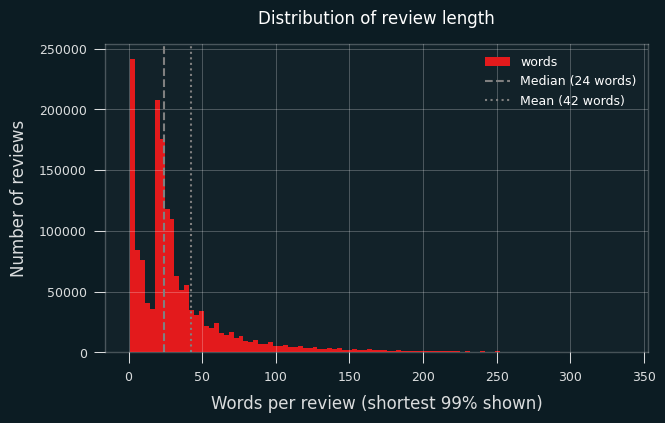

Mean: 42 words | Median: 24 words | Skewness: 17.7


In [ ]:
words = eda["words"]
mean, median, skew = words.mean(), words.median(), words.skew()

ax = words[words <= words.quantile(0.99)].plot(kind="hist", bins=100, figsize=(7, 4)) # histogram so that we can see the distribution
ax.axvline(median, color="gray", linestyle="--", linewidth=1.5, label=f"Median ({median:.0f} words)")
ax.axvline(mean, color="gray", linestyle=":", linewidth=1.5, label=f"Mean ({mean:.0f} words)")
ax.set(title="Distribution of review length", xlabel="Words per review (shortest 99% shown)", ylabel="Number of reviews")
ax.legend(frameon=False)
plt.show()

print(f"Mean: {mean:.0f} words | Median: {median:.0f} words | Skewness: {skew:.1f}")

As the histogram shows, most reviews are short, but a long tail stretches to the right and pulls the mean above the median. The skewness is far above $1$, so review lengths are heavily right-skewed. This makes `ANOVA` unreliable. Instead we use the `Kruskal–Wallis H test`, a rank-based alternative to one-way ANOVA that compares the five rating groups without assuming normality:

$$
\begin{aligned}
H_0 &: \text{review length has the same distribution for every rating} \\
H_1 &: \text{at least one rating differs}
\end{aligned}
\qquad \alpha = 0.05
$$

$$
H = \frac{12}{N(N+1)} \sum_{r=1}^{5} \frac{R_r^2}{n_r} - 3(N+1) \qquad\qquad \eta^2_H = \frac{H - k + 1}{N - k}
$$

Here, $R_r$ is the sum of ranks in rating group $r$, $n_r$ is the size of that group, and $k = 5$ is the number of groups. For $\eta^2_H$, $0.01$ is small, $0.06$ is medium, and $0.14$ is large.

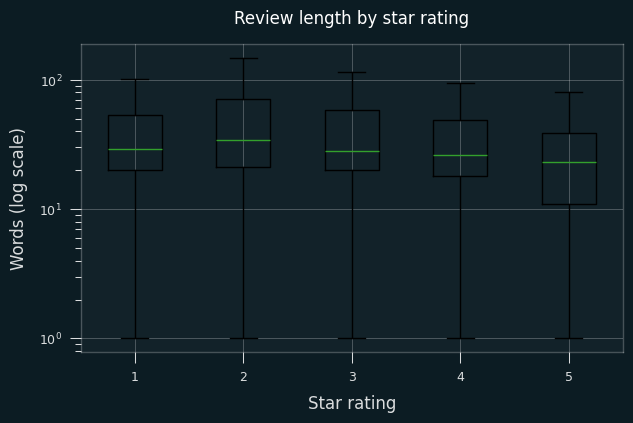

H = 18,006, p < 0.001, η² = 0.011
Median words by rating: {1: 29, 2: 34, 3: 28, 4: 26, 5: 23}
Overall median: 24 words | 95th percentile: 133 words


In [ ]:
groups = [eda.loc[eda["rating"] == r, "words"] for r in range(1, 6)]
H, p = kruskal(*groups)
eta2 = (H - 5 + 1) / (len(eda) - 5)

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(groups, showfliers=False)
ax.set_yscale("log")
ax.set(title="Review length by star rating", xlabel="Star rating", ylabel="Words (log scale)")
plt.show()

print(f"H = {H:,.0f}, {fmt_p(p)}, η² = {eta2:.3f}")
print("Median words by rating:", eda.groupby("rating")["words"].median().astype(int).to_dict())
print(f"Overall median: {eda['words'].median():.0f} words | 95th percentile: {eda['words'].quantile(0.95):.0f} words")

##### Conclusion 2: Reviews are short, and length differs only slightly by rating

We reject $H_0$ ($H = 18{,}006$, $p < 0.001$), but the effect is small ($\eta^2_H = 0.011$). The rating accounts for only about $1\%$ of the variation in review length. The length distributions overlap heavily, so length alone says little about the rating. The model will have to rely on what the review actually says.

For our further experiments, it's worth noting that the median review has only $24$ words, and $95\%$ of reviews have at most $133$ words. A maximum input length of $256$ tokens will therefore fit almost every review without truncation.

#### 3.3 Rating Trend Over Time

The reviews span many years. If ratings drift over time, a split by date would give training and test sets with different class mixes. We test for a monotonic trend between review year $Y$ and star rating $R$ with **Spearman's rank correlation**, which works on ranks and therefore suits two ordinal variables. Only years with at least $1{,}000$ reviews are included.

$$
\rho_s = \operatorname{corr}\big(\operatorname{rank}(Y),\ \operatorname{rank}(R)\big)
$$

$$
\begin{aligned}
H_0 &: \rho_s = 0 \quad \text{(no trend)} \\
H_1 &: \rho_s \neq 0
\end{aligned}
\qquad \alpha = 0.05
$$

For $|\rho_s|$, values below $0.1$ are negligible, $0.1$ to $0.3$ weak, $0.3$ to $0.5$ moderate, and above $0.5$ strong.

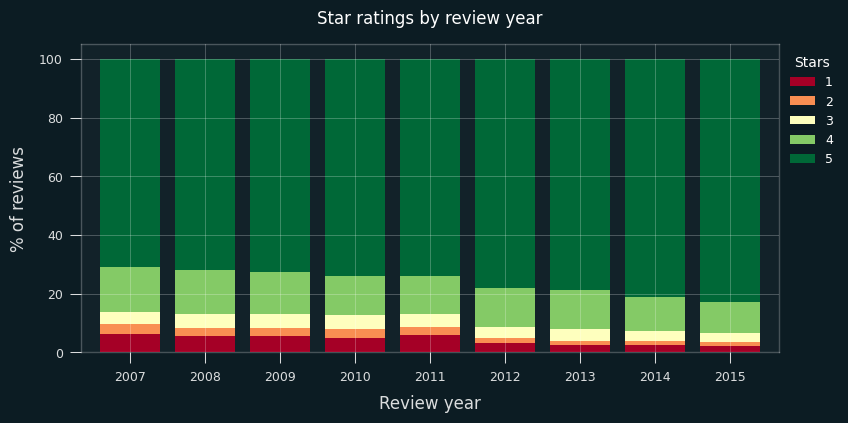

Spearman ρ = 0.063, p < 0.001 | 1,681,247 reviews across 9 years
5★ share: lowest 70.7% (2007), highest 82.7% (2015)


In [ ]:
counts = eda["year"].value_counts()
dated = eda[eda["year"].isin(counts[counts >= 1000].index)].astype({"year": int})

rho, p = spearmanr(dated["year"], dated["rating"])

shares = pd.crosstab(dated["year"], dated["rating"], normalize="index") * 100
ax = shares.plot(kind="bar", stacked=True, colormap="RdYlGn", rot=0, width=0.8, figsize=(9, 4))
ax.set(title="Star ratings by review year", xlabel="Review year", ylabel="% of reviews")
ax.legend(title="Stars", frameon=False, bbox_to_anchor=(1, 1))
plt.show()

print(f"Spearman ρ = {rho:.3f}, {fmt_p(p)} | {len(dated):,} reviews across {dated['year'].nunique()} years")
print(f"5★ share: lowest {shares[5].min():.1f}% ({shares[5].idxmin()}), highest {shares[5].max():.1f}% ({shares[5].idxmax()})")

##### Conclusion 3: Ratings become slightly more positive over time

We reject $H_0$ ($\rho_s = 0.063$, $p < 0.001$), but the trend is negligible in strength, since $|\rho_s| < 0.1$. Almost all reviews ($1{,}681{,}247$ of $1{,}681{,}368$) were written between 2007 and 2015. Over this period, the share of 5★ reviews rises from $70.7\%$ in 2007 to $82.7\%$ in 2015, and 1★ and 2★ reviews become rarer, with most of the shift happening after 2011. Because the class mix changes from year to year, a split by date would give training and test sets with different class proportions. We therefore split the data randomly, stratified by class, so that every subset covers the same years.

#### 3.4 Conclusion

We explored the dataset with three different statistical tests, each paired with an effect size and a plot: a chi-square goodness-of-fit test for the rating distribution, a Kruskal–Wallis $H$ test for review length across ratings, and a Spearman rank correlation for the trend in ratings over time. With over $1.6$ million reviews, all three tests are significant, so the effect sizes decide which findings actually matter.

| Test | Finding | Effect size | Decision |
|---|---|---|---|
| Chi-square goodness-of-fit | Ratings are far from uniform: $79.6\%$ are 5★ | $w = 1.50$ (large) | Three classes, stratified split, macro-F1 |
| Kruskal–Wallis $H$ | Length differs slightly by rating; median $24$ words | $\eta^2_H = 0.011$ (small) | Maximum input length of $256$ tokens |
| Spearman correlation | Ratings drift upward over time | $\rho_s = 0.063$ (negligible) | Random split instead of a split by date |

### A1. Select the text and create sentiment labels

We use the cleaned review text as input and group ratings into three classes:

| Rating | Label | Class |
|---|---:|---|
| 1–2 stars | 0 | Negative |
| 3–4 stars | 1 | Neutral |
| 5 stars | 2 | Positive |

`“Neutral”` is the name of our middle rating group and includes moderately favorable reviews, incuding those that had $4$ stars. The labels are rating-based and not our manual assessment of each individual review.

We retain review IDs and original ratings for reference.

In [ ]:
reviews = df_preprocessed[
    ["review_id", "clean_review", "star_rating"]
].rename(columns={"clean_review": "text"}).copy()

reviews["star_rating"] = reviews["star_rating"].astype(int)

rating_to_label = {
    1: 0,
    2: 0,
    3: 1,
    4: 1,
    5: 2
}

reviews["labels"] = reviews["star_rating"].map(rating_to_label)

### A2. Check repeated review text

Earlier cleaning checked for identical full rows. Different review IDs can still contain the same text, and text cleaning can make previously different strings identical.

Here, we compare cleaned text alone. We keep one copy when repeated text has the same sentiment label. If identical text has conflicting sentiment labels, we exclude that text from this text-only dataset.

We do this before splitting so identical cleaned text cannot appear in both training and evaluation. The original cleaned DataFrame remains unchanged.

In [ ]:
labels_per_text = (
    reviews.groupby("text")["labels"]
    .transform("nunique")
)

conflicting_rows = labels_per_text.gt(1).sum()
reviews = reviews.loc[labels_per_text.eq(1)].copy() # keeping only rows that aren't conflicting

duplicate_rows = reviews.duplicated(subset="text").sum()
reviews = reviews.drop_duplicates(subset="text").reset_index(drop=True)

print("Rows excluded because their text had conflicting labels:", conflicting_rows)
print("Additional repeated-text rows removed:", duplicate_rows)
print("Reviews retained:", len(reviews))

Rows excluded because their text had conflicting labels: 153185
Additional repeated-text rows removed: 81980
Reviews retained: 1446203


### A3. Create training, validation, and test splits

We allocate 70% of reviews to training, 15% to validation, and 15% to testing. Stratification preserves approximately the same class proportions across splits.

We save these assignments so everyone uses the same examples for training and evaluation.

In [ ]:
train_df, remaining_df = train_test_split(
    reviews,
    test_size=0.30,
    random_state=SEED,
    stratify=reviews["labels"]
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_df["labels"]
)

data = DatasetDict({
    "train": Dataset.from_pandas(train_df, preserve_index=False),
    "val": Dataset.from_pandas(val_df, preserve_index=False),
    "test": Dataset.from_pandas(test_df, preserve_index=False)
})

data

DatasetDict({
    train: Dataset({
        features: ['review_id', 'text', 'star_rating', 'labels'],
        num_rows: 1012342
    })
    val: Dataset({
        features: ['review_id', 'text', 'star_rating', 'labels'],
        num_rows: 216930
    })
    test: Dataset({
        features: ['review_id', 'text', 'star_rating', 'labels'],
        num_rows: 216931
    })
})

### A4. Export the prepared datasets

We save each split as a compressed Parquet table. Each row contains cleaned text, a sentiment label, a review ID, and the original rating.

The metadata file records the label mapping, random seed, split sizes, and duplicate-handling policy. We upload these files to a versioned GitHub release so teammates can download the same prepared data.

Tokenization happens separately in Section C.

In [ ]:
EXPORT_DIR = Path("/content/prepared_data")
EXPORT_DIR.mkdir(exist_ok=True)

for split, dataset in data.items():
    path = EXPORT_DIR / f"{split}.parquet"
    dataset.to_parquet(str(path))
    print(f"{path.name}: {path.stat().st_size / 1024**2:.1f} MiB")

metadata = {
    "version": "data-v1",
    "seed": SEED,
    "rating_to_label": rating_to_label,
    "id2label": id2label,
    "split_proportions": {
        "train": 0.70,
        "val": 0.15,
        "test": 0.15
    },
    "split_sizes": {
        split: len(dataset) for split, dataset in data.items()
    },
    "duplicate_policy": (
        "Exclude identical cleaned texts with conflicting sentiment labels, "
        "then retain one row per text."
    )
}

with open(EXPORT_DIR / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

Creating parquet from Arrow format:   0%|          | 0/4 [00:00<?, ?ba/s]

train.parquet: 175.0 MiB


Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

val.parquet: 37.6 MiB


Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

test.parquet: 37.6 MiB


## B. Start here to use the prepared datasets

Run Setup first, then this section. You can skip the raw-data loading, cleaning, EDA, label creation, and splitting in Section A.

We download the fixed splits from RevVue’s data-v1 release. Labels are already assigned: **0 = negative (1–2 stars), 1 = neutral (3–4 stars), 2 = positive (5 stars)**.

After loading, continue to Section C.

In [3]:
BASE_URL = (
    "https://github.com/devanshmayatra/revvue/"
    "releases/download/data-v1"
)

data = load_dataset(
    "parquet",
    data_files={
        "train": f"{BASE_URL}/train.parquet",
        "val": f"{BASE_URL}/val.parquet",
        "test": f"{BASE_URL}/test.parquet"
    }
)

data

Generating train split: 0 examples [00:00, ? examples/s]

Generating val split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['review_id', 'text', 'star_rating', 'labels'],
        num_rows: 1012342
    })
    val: Dataset({
        features: ['review_id', 'text', 'star_rating', 'labels'],
        num_rows: 216930
    })
    test: Dataset({
        features: ['review_id', 'text', 'star_rating', 'labels'],
        num_rows: 216931
    })
})

## C. Tokenization and batching

Both data routes produce the same DatasetDict. We now convert the review text into inputs for the selected model.

### C1. Tokenize the text

The tokenizer converts text into token IDs and truncates reviews to at most 256 tokens. Padding happens later, within each batch.

When changing models, please rerun Section C with the appropriate tokenizer while reusing the same data splits, otherwise, the experiments won't work as expected.

In [4]:
tokenizer = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

data_tokenized = data.map(
    tokenize_batch,
    batched=True,
    remove_columns=[
        column for column in data["train"].column_names
        if column != "labels"
    ]
)

data_tokenized

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1012342 [00:00<?, ? examples/s]

Map:   0%|          | 0/216930 [00:00<?, ? examples/s]

Map:   0%|          | 0/216931 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1012342
    })
    val: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 216930
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 216931
    })
})

### C2. Create batches

The collator pads each batch to its longest review and converts the values into PyTorch tensors. Training examples are shuffled; validation and test examples keep their existing order.

In [5]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

train_dataloader = DataLoader(
    data_tokenized["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator,
    generator=torch.Generator().manual_seed(SEED)
)

val_dataloader = DataLoader(
    data_tokenized["val"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

test_dataloader = DataLoader(
    data_tokenized["test"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

### C3. Inspect a batch

Each batch contains token IDs, attention masks, segment IDs, and one label per review. Attention masks distinguish actual tokens from padding.

The pretrained model’s internal embedding layer will convert token IDs into vectors. No separate embedding calculation is required during data preparation.

In [6]:
batch = next(iter(train_dataloader))

for name, values in batch.items():
    print(name, values.shape)

labels torch.Size([16])
input_ids torch.Size([16, 197])
token_type_ids torch.Size([16, 197])
attention_mask torch.Size([16, 197])


All good, we can now proceed to the experimental part.

## D. BERT-tiny experiments

### D1. Baseline preparation

We use the pretrained `prajjwal1/bert-tiny` checkpoint with a new three-class classifier for negative, neutral, and positive reviews. Both the encoder and classifier are fine-tuned on the shared `data-v1` training split.

The baseline starts with the following hyperparameters:

| Hyperparameter | Value |
|---|---:|
| Learning rate | 0.00002 |
| Batch size | 16 |
| Weight decay | 0.01 |

#### Calculating class weights

The sentiment classes remain imbalanced after grouping the ratings. To give minority-class examples more influence during training, we use class-weighted cross-entropy.

First, `np.bincount` counts the training examples belonging to each label, producing the counts for negative, neutral, and positive reviews. We then calculate:

$$
w_c = \frac{N}{3n_c}
$$

where:
- $N$ is the total number of training reviews;
- $n_c$ is the number of training reviews in class $c$;
- $3$ is the number of sentiment classes.

The weight is inversely proportional to the class frequency. For example, if one class has ten times fewer reviews than another, its examples receive ten times larger weights.

This formula gives each class the same total weight across the training set:

$$
n_c w_c = \frac{N}{3}.
$$

The weights are calculated from training labels only, and the cell below prints their actual values. We pass them to cross-entropy through its `weight` argument, increasing the relative contribution of errors on rarer classes.

#### Evaluation

We report `accuracy` and `macro-F1`. Validation macro-F1 determines which checkpoint to retain because it averages the three class-specific F1 scores equally. The same loss weighting and evaluation metrics are used throughout the BERT-tiny experiments, including Optuna tuning.

In [7]:
RUNS_DIR = Path("bert_tiny_runs")
RESULTS_DIR = Path("bert_tiny_results")
RESULTS_DIR.mkdir(exist_ok=True)

BASE_PARAMS = {
    "learning_rate": 2e-5,
    "batch_size": 16,
    "weight_decay": 0.01,
}

In [8]:
def compute_metrics(eval_pred): # func for computing metrics
    logits, labels = eval_pred
    predictions = logits.argmax(axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    }

In [9]:
train_labels = np.asarray(data_tokenized["train"]["labels"])
counts = np.bincount(train_labels, minlength=3)

class_weights = torch.tensor(
    counts.sum() / (3 * counts),
    dtype=torch.float32,
)

print(dict(zip(id2label.values(), class_weights.tolist())))

{'negative': 6.974646091461182, 'neutral': 2.049370765686035, 'positive': 0.4221780300140381}


Clearly, negative reviews have more weight because there are much fewer if them, compared to negative and positive ones.

In [10]:
def weighted_loss(outputs, labels, num_items_in_batch=None):
    return F.cross_entropy(
        outputs.logits,
        labels,
        weight=class_weights.to(outputs.logits.device),
    )

### D1. Training setup

We use the same training function throughout the experiments. Each run starts from the original pretrained checkpoint and restores its best validation checkpoint after training.

In [11]:
def run_experiment(name, params, train_set, val_set, epochs=3):
    set_seed(SEED)
    run_dir = RUNS_DIR / name

    config = BertConfig.from_pretrained(
        MODEL_NAME,
        num_labels=3,
        id2label=id2label,
        label2id=label2id,
    )

    model = BertForSequenceClassification.from_pretrained(
        MODEL_NAME,
        config=config,
    )

    args = TrainingArguments(
        output_dir=str(run_dir),
        num_train_epochs=epochs,
        learning_rate=params["learning_rate"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        weight_decay=params["weight_decay"],
        warmup_steps=0.1,
        optim="adamw_torch",
        gradient_accumulation_steps=1,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        seed=SEED,
        data_seed=SEED,
        fp16=torch.cuda.is_available(),
        report_to="none",
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_set,
        eval_dataset=val_set,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        compute_loss_func=weighted_loss,
        callbacks=[
            EarlyStoppingCallback(early_stopping_patience=2)
        ],
    )

    trainer.train()

    # evaluation of the restored best checkpoint
    metrics = trainer.evaluate()
    metrics["epochs_run"] = trainer.state.epoch

    trainer.save_model(str(run_dir / "best_model"))
    pd.DataFrame(trainer.state.log_history).to_csv(
        run_dir / "history.csv", index=False
    )

    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()

    return metrics

### D2. Baseline run

First, we train the baseline on the complete prepared training split and record its validation results.

In [12]:
baseline_metrics = run_experiment(
    "baseline",
    BASE_PARAMS,
    data_tokenized["train"],
    data_tokenized["val"],
    epochs=5,
)

baseline_metrics

config.json:   0%|          | 0.00/285 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 17.8MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were 

model.safetensors: reconstructing file:   0%|          |  0.00B / 17.7MB            

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.639209,0.702898,5,0.783008,0.680151


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'eval_loss': 0.702898383140564,
 'eval_accuracy': 0.7830083437053428,
 'eval_macro_f1': 0.6801509291597784,
 'epochs_run': 5.0}

## E. Hyperparameter tuning with Optuna

We search learning rate, batch size, and weight decay over six trials.

Every trial uses the same stratified subsets: $30,000$ training reviews and $5,000$ validation reviews. These are sampled within the existing splits. Maximum input length stays fixed at $256$ tokens. For hyperparamter tuning we are using `optuna`.